# 10 Model comparison

Every model so far, side by side and scored the same way: the classical models from 07a, the time-series models
from 07c to 07h (SARIMAX, Theta, Prophet, AutoTS, the combination, the Box-Cox ETS and the building blocks), the best
time-series model (the combination, fitted on all 726 products in 09), and seasonal naive as the baseline. Most of the
comparison is on the 150-product sample, because that is where every model was fitted; seasonal naive, ETS, the best
model and the runner-up (09b) also have scores on all 726 products. On the sample the best model's forecasts are 07h's combination.
We test whether the differences are real, look at bias, and then look for the places where the simple models win.

## Load

In [1]:
import sys, json, warnings
sys.path.append("../src")
from config import BEST_NAME
BEST_SHORT = BEST_NAME.split(" (")[0]      # the best time-series model from 07h, stored as 'best'
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import ROOT, INTERIM, PROCESSED, TABLES, FIGS, CHECKPOINTS, SEED, CATEGORIES, ORIGINS, EVAL_ORIGINS, FIG_STYLE, NAMES, COLORS
from metrics import all_errors, mase_scale, paired_test
from evaluation import METRICS, score, summarise, paired_family

plt.rcParams.update(FIG_STYLE)
written = []
long_df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                     for c in ["foods", "hobbies", "household"]], ignore_index=True)
long_df["category"] = long_df["item_id"].str.split("_").str[0]
saved = pd.read_parquet(PROCESSED / "backtest_forecasts.parquet")
err = pd.read_csv(PROCESSED / "backtest_errors.csv", parse_dates=["origin"])
scales = err[["item_id", "origin", "mase_scale"]].drop_duplicates()
sample = pd.read_csv(TABLES / "classical_sample_items.csv")
ck = CHECKPOINTS / "items"
parts = [pd.read_parquet(ck / f"{i}.parquet").assign(item_id=i) for i in sample["item_id"]]
classical_fc = pd.concat(parts, ignore_index=True)
totals = {cat: long_df[long_df["category"] == cat].groupby("date")["sales"].sum() for cat in CATEGORIES}
totals["CA_TOTAL"] = long_df.groupby("date")["sales"].sum()
agg_fc = pd.concat([pd.read_parquet(ck / f"_agg_{k}.parquet").assign(item_id=f"_agg_{k}") for k in totals], ignore_index=True)

# the time-series models of 07c to 07h. Their SARIMA, ARIMA and seasonal naive are the 07a forecasts, so they are not
# added twice; their ETS is the Box-Cox version tuned in 07d, kept apart from the 07a ETS.
TS = {"ets": "ets_boxcox", "sarimax": "sarimax", "theta": "theta", "prophet": "prophet", "autots": "autots",
      "combination": "combination", "combination_weighted": "combination_weighted",
      "ar": "ar", "ma": "ma", "arma": "arma", "arimax": "arimax"}
ts_fc = pd.read_parquet(TABLES / "ts_forecasts.parquet", columns=["item_id", "origin", "date", "model", "forecast"],
                        filters=[("model", "in", list(TS))])
ts_fc = ts_fc[ts_fc["origin"].isin(ORIGINS)].assign(model=lambda d: d["model"].map(TS))
print(f"{len(classical_fc):,} classical rows on the sample, {len(ts_fc):,} time-series rows, "
      f"{len(saved):,} rows in the full forecast file")

117,600 classical rows on the sample, 323,400 time-series rows, 1,295,952 rows in the full forecast file


## Every model on the 150 products

In [2]:
reuse = saved[saved["item_id"].isin(sample["item_id"]) & (saved["variant"] == "static")
              & saved["model"].isin(["seasonal_naive", "ets", "best"])][["item_id", "origin", "date", "model", "forecast"]]
fc = pd.concat([classical_fc[["item_id", "origin", "date", "model", "forecast"]], reuse, ts_fc], ignore_index=True)
fc = fc.merge(long_df[["item_id", "date", "sales"]].rename(columns={"sales": "actual"}), on=["item_id", "date"])
fc = fc.merge(sample[["item_id", "category"]], on="item_id")
fc.to_parquet(TABLES / "comparison_forecasts.parquet", index=False)
written.append(TABLES / "comparison_forecasts.parquet")

m = score(fc, scales).merge(sample, on="item_id")
m.to_csv(TABLES / "comparison_metrics_item_origin.csv", index=False)
written.append(TABLES / "comparison_metrics_item_origin.csv")

ORDER = ["seasonal_naive", "ets", "hw_add", "hw_mul", "arima", "sarima", "best"]
TS_ORDER = list(TS.values())
CONTENDERS = ["seasonal_naive", "ets_boxcox", "sarima", "sarimax", "theta", "prophet", "autots", "combination"]   # 07h's eight
ev = m[m["origin"].isin(EVAL_ORIGINS)]
per_item = ev.groupby(["item_id", "category", "break_item", "model"], as_index=False)[METRICS + ["mape_excluded"]].mean()
summary = summarise(per_item, ORDER + TS_ORDER, CATEGORIES)
summary.to_csv(TABLES / "comparison_metrics_summary.csv", index=False)
written.append(TABLES / "comparison_metrics_summary.csv")
show = summary[summary["category"] == "ALL"].set_index("model").loc[ORDER]
print(show[[f"median_{k}" for k in METRICS]].round(3).to_string())
print("\nmedian MASE by category:")
print(summary.pivot(index="model", columns="category", values="median_mase").loc[ORDER, ["ALL"] + CATEGORIES].round(3).to_string())

                median_rmse  median_mae  median_mape  median_smape  median_wape  median_mase
model                                                                                       
seasonal_naive        6.039       4.720        0.753         0.616        0.581        0.973
ets                   4.498       3.511        0.595         0.471        0.437        0.756
hw_add                4.560       3.560        0.595         0.480        0.442        0.757
hw_mul                4.554       3.586        0.595         0.482        0.439        0.761
arima                 4.822       3.775        0.638         0.484        0.458        0.794
sarima                4.445       3.522        0.603         0.474        0.435        0.755
best                  4.392       3.499        0.586         0.469        0.437        0.747

median MASE by category:
category          ALL  FOODS  HOBBIES  HOUSEHOLD
model                                           
seasonal_naive  0.973  0.931    0.978  

## The eight time-series contenders, on the same products

07h's headline, scored again here with this notebook's code from the same forecasts, so that every model sits in one
table. The median RMSE has to match 07h's exactly. 07h's paired tests against SARIMA are in `ts_tests.csv`.

In [3]:
everything = summary[summary["category"] == "ALL"].set_index("model")
cont = everything.loc[CONTENDERS]
print(cont[[f"median_{k}" for k in METRICS]].rename(index=NAMES).round(3).to_string())
head = pd.read_csv(TABLES / "ts_headline.csv", index_col="model")
ref07h = head.loc[[{"ets_boxcox": "ets"}.get(x, x) for x in CONTENDERS], "rmse"].to_numpy()
print(f"\nlargest difference in median RMSE against 07h: {np.abs(cont['median_rmse'].to_numpy() - ref07h).max():.1e}")
print("\nlowest median per measure:", {k: NAMES[cont[f"median_{k}"].idxmin()] for k in METRICS})
print("\nthe building blocks (07c) and the second combination:")
print(everything.loc[["ar", "ma", "arma", "arimax", "combination_weighted"], [f"median_{k}" for k in METRICS]]
      .rename(index=NAMES).round(3).to_string())

                             median_rmse  median_mae  median_mape  median_smape  median_wape  median_mase
model                                                                                                    
Seasonal naive                     6.039       4.720        0.753         0.616        0.581        0.973
Damped ETS, Box-Cox (tuned)        4.513       3.543        0.560         0.474        0.434        0.744
SARIMA                             4.445       3.522        0.603         0.474        0.435        0.755
SARIMAX                            4.583       3.650        0.609         0.466        0.441        0.760
Theta                              4.541       3.510        0.602         0.480        0.442        0.756
Prophet                            4.913       3.859        0.622         0.482        0.445        0.760
AutoTS                             4.848       3.885        0.626         0.502        0.466        0.831
Combination                        4.392      

## Are the differences real?

Paired Wilcoxon tests on each product's MASE, Holm-corrected within each group: SARIMA and Holt-Winters against
seasonal naive, and the best model against each of the others.

In [4]:
wide = per_item.pivot(index="item_id", columns="model", values="mase")
tests = pd.DataFrame(paired_family(wide, [("sarima", "seasonal_naive"), ("hw_add", "seasonal_naive")], "H1", seed=SEED)
                     + paired_family(wide, [("best", x) for x in ["seasonal_naive", "ets", "hw_add", "arima", "sarima"]], "H2", seed=SEED))
tests.to_csv(TABLES / "comparison_tests.csv", index=False)
written.append(TABLES / "comparison_tests.csv")
tests[["hypothesis", "model_a", "model_b", "n", "median_diff", "ci_low", "ci_high", "share_improved", "p_holm", "a_better"]].round(4)

,hypothesis,model_a,model_b,n,median_diff,ci_low,ci_high,share_improved,p_holm,a_better
0,H1,sarima,seasonal_naive,150,-0.2234,-0.2370,-0.2000,0.9733,0.0,True
1,H1,hw_add,seasonal_naive,150,-0.2184,-0.2328,-0.2071,0.9667,0.0,True
2,H2,best,seasonal_naive,150,-0.2318,-0.2442,-0.2132,0.9933,0.0,True
3,H2,best,ets,150,-0.0074,-0.0110,-0.0033,0.6733,0.0,True
4,H2,best,hw_add,150,-0.0077,-0.0114,-0.0050,0.7533,0.0,True
5,H2,best,arima,150,-0.0339,-0.0468,-0.0249,0.8800,0.0,True
6,H2,best,sarima,150,-0.0084,-0.0122,-0.0057,0.6800,0.0,True


## The totals

Classical models fitted on each total; seasonal naive, ETS and the best model added up from the 726 product
forecasts.

In [5]:
agg_rows = []
bottom_up = saved[(saved["variant"] == "static") & saved["model"].isin(["seasonal_naive", "ets", "best"])].copy()
bottom_up["category"] = bottom_up["item_id"].str.split("_").str[0]
for name, s in totals.items():
    mine = agg_fc[agg_fc["item_id"] == f"_agg_{name}"]
    bu = bottom_up if name == "CA_TOTAL" else bottom_up[bottom_up["category"] == name]
    bu = bu.groupby(["origin", "date", "model"], as_index=False)["forecast"].sum()
    for (origin, model), g in pd.concat([mine[["origin", "date", "model", "forecast"]], bu]).groupby(["origin", "model"]):
        if origin not in EVAL_ORIGINS:
            continue
        act = s.reindex(g["date"]).to_numpy()
        sc = mase_scale(s[s.index <= origin].to_numpy())
        agg_rows.append({"series": name, "origin": origin, "model": model,
                         "how": "fitted on total" if model in ["hw_add", "hw_mul", "arima", "sarima"] else "sum of items",
                         **all_errors(act, g["forecast"], sc)})
agg = pd.DataFrame(agg_rows).groupby(["series", "model", "how"], as_index=False)[METRICS].mean()
agg.to_csv(TABLES / "comparison_totals_metrics.csv", index=False)
written.append(TABLES / "comparison_totals_metrics.csv")
print(agg.pivot(index="model", columns="series", values="mase").loc[ORDER].round(3).to_string())

series          CA_TOTAL  FOODS  HOBBIES  HOUSEHOLD
model                                              
seasonal_naive     0.920  0.913    0.967      1.156
ets                0.769  0.813    0.663      0.897
hw_add             0.791  0.849    0.661      0.907
hw_mul             0.770  0.852    0.670      0.889
arima              0.986  0.888    0.757      1.172
sarima             0.849  1.976    0.674      1.145
best               0.796  0.796    0.692      0.917


## On all 726 products: the best model against ETS, and the runner-up

The runner-up of 07h was fitted on all 726 products in `09b_runner_up_all_products`, so it joins the table and
the pairwise tests here.

In [6]:
ev726 = err[err["origin"].isin(EVAL_ORIGINS) & (err["variant"] == "static")]
im = ev726.groupby(["item_id", "category", "model"], as_index=False)["mase"].mean()
ru = pd.read_csv(TABLES / "runner_up_726_scores.csv", parse_dates=["origin"])        # 09b, scored origins only
RUNNER = next(x for x in ru["model"].unique() if x not in ["seasonal_naive", "ets", "best"])
ru = ru[ru["model"] == RUNNER]
im = pd.concat([im, ru.groupby(["item_id", "category", "model"], as_index=False)["mase"].mean()], ignore_index=True)
piv = im.pivot_table(index=["item_id", "category"], columns="model", values="mase").reset_index()
rows = []
for cat in ["ALL", "FOODS", "HOBBIES", "HOUSEHOLD"]:
    d = piv if cat == "ALL" else piv[piv["category"] == cat]
    rows.append({"comparison": "best - ets", "category": cat, **paired_test(d["best"] - d["ets"], seed=SEED)})
best_ets = pd.DataFrame(rows)
best_ets.to_csv(TABLES / "best_vs_ets_test.csv", index=False)
written.append(TABLES / "best_vs_ets_test.csv")
print(best_ets[["category", "n", "median_diff", "ci_low", "ci_high", "share_improved", "rank_biserial", "p_value"]].round(5).to_string(index=False))

unr = []
for model in ["seasonal_naive", "ets", "best", RUNNER, "tsb"]:
    d = im[im["model"] == model]
    for cat in ["ALL"] + sorted(d["category"].unique()):
        x = d if cat == "ALL" else d[d["category"] == cat]
        unr.append({"model": model, "category": cat, "n_items": len(x), "median_item_mase": x["mase"].median(),
                    "mean_item_mase": x["mase"].mean()})
unrounded = pd.DataFrame(unr)
unrounded.to_csv(TABLES / "model_mase_unrounded.csv", index=False)
written.append(TABLES / "model_mase_unrounded.csv")

rows = []
for a, b in [("best", "seasonal_naive"), ("best", "ets"), ("ets", "seasonal_naive"), (RUNNER, "best"),
             (RUNNER, "ets")]:
    for cat in ["ALL", "FOODS", "HOBBIES", "HOUSEHOLD"]:
        d = piv if cat == "ALL" else piv[piv["category"] == cat]
        rows.append({"model_a": a, "model_b": b, "category": cat, **paired_test(d[a] - d[b], seed=SEED)})
pairwise = pd.DataFrame(rows)
pairwise.to_csv(TABLES / "model_pairwise_tests.csv", index=False)
written.append(TABLES / "model_pairwise_tests.csv")
pairwise[["model_a", "model_b", "category", "n", "median_diff", "ci_low", "ci_high", "share_improved", "p_value"]].round(5)

 category   n  median_diff   ci_low  ci_high  share_improved  rank_biserial  p_value
      ALL 726     -0.00557 -0.00704 -0.00413         0.62810       -0.42779  0.00000
    FOODS 337     -0.00927 -0.01248 -0.00600         0.67062       -0.49924  0.00000
  HOBBIES 106     -0.00404 -0.00990 -0.00063         0.61321       -0.46711  0.00003
HOUSEHOLD 283     -0.00262 -0.00518 -0.00099         0.58304       -0.31071  0.00001


,model_a,model_b,category,n,median_diff,ci_low,ci_high,share_improved,p_value
0,best,seasonal_naive,ALL,726,-0.21586,-0.22583,-0.20719,0.98209,0.00000
1,best,seasonal_naive,FOODS,337,-0.18770,-0.20241,-0.17661,0.96736,0.00000
2,best,seasonal_naive,HOBBIES,106,-0.25847,-0.28049,-0.24105,0.99057,0.00000
3,best,seasonal_naive,HOUSEHOLD,283,-0.22920,-0.24411,-0.21709,0.99647,0.00000
4,best,ets,ALL,726,-0.00557,-0.00704,-0.00413,0.62810,0.00000
5,best,ets,FOODS,337,-0.00927,-0.01248,-0.00600,0.67062,0.00000
6,best,ets,HOBBIES,106,-0.00404,-0.00990,-0.00063,0.61321,0.00003
7,best,ets,HOUSEHOLD,283,-0.00262,-0.00518,-0.00099,0.58304,0.00001
8,ets,seasonal_naive,ALL,726,-0.21026,-0.21916,-0.19873,0.96006,0.00000
9,ets,seasonal_naive,FOODS,337,-0.17283,-0.18629,-0.15832,0.92582,0.00000


## Bias: do the models guess too high or too low?

Bias is total forecast over total sales, minus 1. We report it pooled and as the median over products, with a
bootstrap interval for the median.

In [7]:
rng = np.random.default_rng(SEED)
POL_BIAS = [("seasonal_naive", "static"), ("ets", "static"), ("best", "static"), ("best", "adaptive")]
saved["category"] = saved["item_id"].str.split("_").str[0]
e = saved[saved["origin"].isin(EVAL_ORIGINS)]
rows = []
for model, variant in POL_BIAS:
    d = e[(e["model"] == model) & (e["variant"] == variant)]
    for cat in ["ALL", "FOODS", "HOBBIES", "HOUSEHOLD"]:
        x = d if cat == "ALL" else d[d["category"] == cat]
        per = x.groupby("item_id")[["forecast", "actual"]].sum()
        per = per[per["actual"] > 0]
        b = (per["forecast"] / per["actual"] - 1).to_numpy()
        boots = np.median(rng.choice(b, size=(2000, len(b))), axis=1)
        rows.append({"model": model, "variant": variant, "category": cat, "n_items": len(b),
                     "pooled_bias": x["forecast"].sum() / x["actual"].sum() - 1,
                     "median_item_bias": np.median(b), "ci_low": np.quantile(boots, 0.025), "ci_high": np.quantile(boots, 0.975),
                     "share_items_under": np.mean(b < 0)})
bias = pd.DataFrame(rows)
bias.to_csv(TABLES / "forecast_bias.csv", index=False)
written.append(TABLES / "forecast_bias.csv")

item_bias = []
for model, variant in POL_BIAS:
    d = e[(e["model"] == model) & (e["variant"] == variant)].groupby("item_id")[["forecast", "actual"]].sum()
    item_bias.append(pd.DataFrame({"item_id": d.index, "model": model, "variant": variant,
                                   "forecast_units": d["forecast"].to_numpy(), "actual_units": d["actual"].to_numpy(),
                                   "bias": np.where(d["actual"] > 0, d["forecast"] / d["actual"] - 1, np.nan)}))
item_bias = pd.concat(item_bias, ignore_index=True)
item_bias.to_csv(TABLES / "item_bias.csv", index=False)
written.append(TABLES / "item_bias.csv")
bias[bias["category"] == "ALL"].round(4)

,model,variant,category,n_items,pooled_bias,median_item_bias,ci_low,ci_high,share_items_under
0,seasonal_naive,static,ALL,726,-0.0078,0.0014,-0.0052,0.0083,0.4904
4,ets,static,ALL,726,-0.0088,-0.0073,-0.0133,-0.0011,0.5399
8,best,static,ALL,726,-0.0157,-0.0213,-0.0272,-0.0148,0.6212
12,best,adaptive,ALL,726,-0.0136,-0.0183,-0.0253,-0.0130,0.5992


## One table for everything

In [8]:
overview = show[["n_items", "median_mase", "median_rmse", "median_mae", "median_smape", "median_wape"]].copy()
mase726 = unrounded[unrounded["category"] == "ALL"].set_index("model")["median_item_mase"]
overview["median_mase_726"] = overview.index.map(mase726)
overview["beats_naive_share"] = [(wide[x] < wide["seasonal_naive"]).mean() if x != "seasonal_naive" else np.nan for x in overview.index]
overview["beats_best_share"] = [(wide[x] < wide["best"]).mean() if x != "best" else np.nan for x in overview.index]
overview = overview.rename(index=NAMES)
overview.to_csv(TABLES / "comparison_overview.csv")
written.append(TABLES / "comparison_overview.csv")
overview.round(3)

,n_items,median_mase,median_rmse,median_mae,median_smape,median_wape,median_mase_726,beats_naive_share,beats_best_share
model,,,,,,,,,
Seasonal naive,150,0.973,6.039,4.720,0.616,0.581,0.976,NaN,0.007
Damped Holt-Winters (ETS),150,0.756,4.498,3.511,0.471,0.437,0.755,0.967,0.327
Holt-Winters additive,150,0.757,4.560,3.560,0.480,0.442,NaN,0.967,0.247
Holt-Winters multiplicative,150,0.761,4.554,3.586,0.482,0.439,NaN,0.947,0.287
ARIMA,150,0.794,4.822,3.775,0.484,0.458,NaN,0.933,0.120
SARIMA,150,0.755,4.445,3.522,0.474,0.435,0.755,0.973,0.320
Combination (best time-series model),150,0.747,4.392,3.499,0.469,0.437,0.747,0.993,NaN


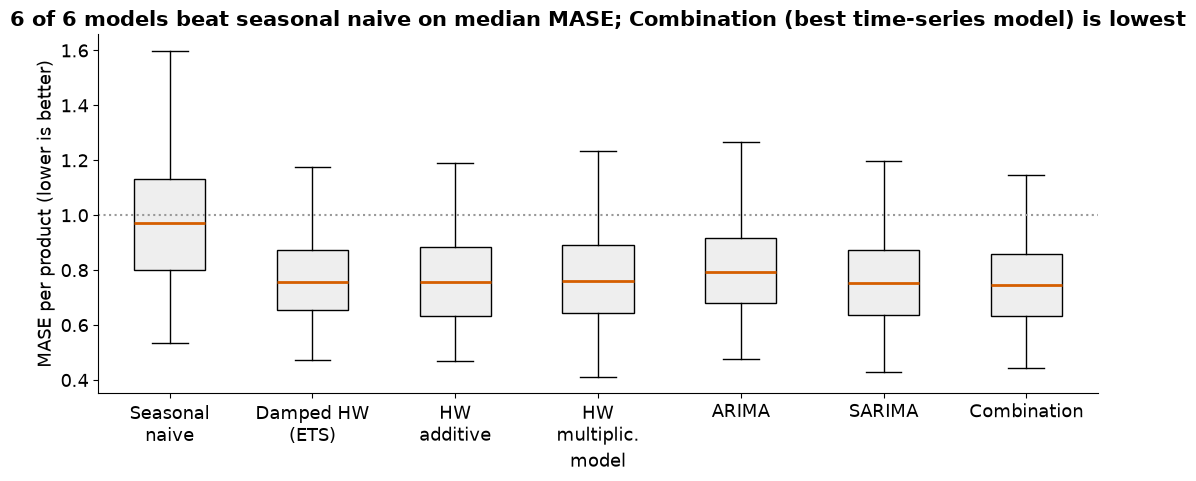

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
data = [wide[x].dropna() for x in ORDER]
ax.boxplot(data, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#EEEEEE"), medianprops=dict(color="#D55E00", lw=2))
SHORT = {"seasonal_naive": "Seasonal\nnaive", "ets": "Damped HW\n(ETS)", "hw_add": "HW\nadditive",
         "hw_mul": "HW\nmultiplic.", "arima": "ARIMA", "sarima": "SARIMA", "best": BEST_SHORT}
ax.set_xticks(range(1, len(ORDER) + 1), [SHORT[x] for x in ORDER])
ax.axhline(1, color="#999999", ls=":")
ax.set_xlabel("model")
ax.set_ylabel("MASE per product (lower is better)")
best = show["median_mase"].idxmin()
n_beat = int((show.drop(index="seasonal_naive")["median_mase"] < show.loc["seasonal_naive", "median_mase"]).sum())
ax.set_title(f"{n_beat} of 6 models beat seasonal naive on median MASE; {NAMES[best]} is lowest")
fig.tight_layout()
fig.savefig(FIGS / "mase_by_model.png")
written.append(FIGS / "mase_by_model.png")
plt.show()

## Where the simple models win

In [10]:
# per product: which model had the lowest MASE?
winner = wide[ORDER].idxmin(axis=1)
print("how often each model is the best of the seven, per product:")
print(winner.value_counts().rename(index=NAMES).to_string())
print(f"\nseasonal naive beats {BEST_SHORT} on {(wide['seasonal_naive'] < wide['best']).mean():.0%} of products, "
      f"ETS beats it on {(wide['ets'] < wide['best']).mean():.0%}, SARIMA on {(wide['sarima'] < wide['best']).mean():.0%}")
cat_best = summary[summary["category"] != "ALL"].loc[lambda x: x.groupby("category")["median_mase"].idxmin()]
print("\nlowest median MASE per category:", dict(zip(cat_best["category"], cat_best["model"].map(NAMES))))
tot_best = agg.loc[agg.groupby("series")["mase"].idxmin()]
print("lowest MASE per total:", dict(zip(tot_best["series"], tot_best["model"].map(NAMES))))

how often each model is the best of the seven, per product:
Combination (best time-series model)    44
Damped Holt-Winters (ETS)               35
SARIMA                                  30
Holt-Winters multiplicative             20
Holt-Winters additive                   14
ARIMA                                    7

seasonal naive beats Combination on 1% of products, ETS beats it on 33%, SARIMA on 32%

lowest median MASE per category: {'FOODS': 'Combination (best time-series model)', 'HOBBIES': 'Damped ETS, Box-Cox (tuned)', 'HOUSEHOLD': 'SARIMA'}
lowest MASE per total: {'CA_TOTAL': 'Damped Holt-Winters (ETS)', 'FOODS': 'Combination (best time-series model)', 'HOBBIES': 'Holt-Winters additive', 'HOUSEHOLD': 'Holt-Winters multiplicative'}


## What we found

Every model beats seasonal naive by a wide margin, and the good ones are close. On the 150 products the median MASE
is 0.973 for seasonal naive, 0.794 for ARIMA, between 0.755 and 0.761 for the other classical models (SARIMA 0.755,
ETS 0.756, additive Holt-Winters 0.757, multiplicative 0.761) and 0.747 for the combination. SARIMA and additive
Holt-Winters beat seasonal naive on about 97% of products (Holm p < 0.001). The combination is ahead of every
classical model product by product: of ETS by 0.007 (better for 67% of products), additive Holt-Winters by 0.008
(75%), SARIMA by 0.008 (68%) and ARIMA by 0.034 (88%), each Holm p < 0.001. The eight time-series contenders scored
here match 07h's medians exactly.

On all 726 products the combination is ahead of ETS too: median MASE 0.7467 against 0.7554, seasonal naive 0.976. It
is better for 63% of products (median difference -0.0056, 95% CI -0.0070 to -0.0041, p < 0.001), and in every
category (FOODS -0.009, HOBBIES -0.004, HOUSEHOLD -0.003). The runner-up, SARIMA, is level with ETS (0.7546, p =
0.19) and behind the combination (+0.0074, p < 0.001).

The simple models still win often. Per product, the combination has the lowest MASE of the seven for 44 of 150
products, ETS for 35, SARIMA for 30, the two Holt-Winters versions for 34 together and ARIMA for 7. ETS beats the
combination on 33% of products and SARIMA on 32%. By category, the combination has the lowest median in FOODS, the
Box-Cox Holt-Winters in HOBBIES and SARIMA in HOUSEHOLD. On the totals, the combination summed over products is best
for FOODS (0.796), ETS for California as a whole (0.769), additive Holt-Winters for HOBBIES (0.661) and multiplicative
Holt-Winters for HOUSEHOLD (0.889). SARIMA fitted directly on the FOODS total goes badly wrong (1.976), which 07b
traced to numerical problems with large values; summing the product forecasts avoids that.

Bias is small, but the combination runs lower than the rest: its total forecast is 1.6% below total sales (62% of
products under-forecast), against 0.9% for ETS and 0.8% for seasonal naive, and most of it is in FOODS.

So the combination is the forecast behind the stock work: it won the pre-registered comparison in 07h, and its lead
over ETS holds on all 726 products, though it is small and other models still win on many products. `07i` asks
which model is best across six measures, with the ties and the stock cost of each.

In the earlier version of this project LightGBM had this place. It had a median MASE of 0.747 on the sample and
0.744 on all 726 products, about the same as the combination, but it under-forecast by 3.6% in total. It was removed
because it is a machine-learning model, not a time-series model.

## What comes next

`11a_uncertainty` asks how honest the uncertainty around these forecasts is, before we turn them into stock decisions.

In [11]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\tables\comparison_forecasts.parquet 4,381 KB
outputs\tables\comparison_metrics_item_origin.csv 3,221 KB
outputs\tables\comparison_metrics_summary.csv 19 KB
outputs\tables\comparison_tests.csv 2 KB
outputs\tables\comparison_totals_metrics.csv 4 KB
outputs\tables\best_vs_ets_test.csv 1 KB
outputs\tables\model_mase_unrounded.csv 1 KB
outputs\tables\model_pairwise_tests.csv 4 KB
outputs\tables\forecast_bias.csv 2 KB
outputs\tables\item_bias.csv 205 KB
outputs\tables\comparison_overview.csv 1 KB
outputs\figures\mase_by_model.png 60 KB
